# 07 — The fly reservoir (mushroom body + projection neurons)

Builds a **reservoir computer from the *Drosophila* mushroom-body connectome** and tests whether it forecasts conflict better than the tuned ridge baseline. Same target, same folds, same tuning budget as notebook 05. **The locked 2021–2025 test set is never scored.**

### The model
- **Network:** the 5,606 mushroom-body neurons (Kenyon cells, MBONs, dopaminergic PAM/PPL neurons, APL) **plus the 285 olfactory projection neurons (PNs)** that feed the Kenyon cells: 5,891 neurons, about 93,000 weighted, signed connections from FlyWire FAFB v783. The wiring is fixed.
- **Input layer:** the 28 features of a country-month drive the PNs through a fixed random matrix `W_in`. The *real* PN→Kenyon-cell wiring then does the sparse expansion. This keeps the mushroom body's own random projection instead of inventing one.
- **Dynamics:** `x(t) = (1 − leak)·x(t−1) + leak·tanh(Wᵀ x(t−1) + drive(t))`, with `W` the connectome rescaled to a chosen spectral radius `rho`. **`rho` is tuned, not a property of the fly.**
- **One reservoir run per country,** from a zero state at the country's first month, then all countries pooled in one ridge readout (the settled design in the project guide). Country *i*'s state never sees country *j*; cross-country effects enter only through the neighbour-conflict feature.
- **Readout:** ridge on `[reservoir states, the 28 raw features]`. Including the raw features means the reservoir can only help *on top of* what ridge already has. States are a fixed random subset of **1,024 units** (the same subset for every network) plus, as a separate variant, the **96 MBONs** (the fly's own readout neurons).
- **Weights:** each neuron's inputs sum to 1 (fraction of postsynaptic input); sign by presynaptic neuron (acetylcholine +, GABA and glutamate −); serotonin, dopamine and octopamine neurons send no signal through `W`.

### Fair comparison
- `N_ITER` random configurations of (`rho`, `input_scale`, `leak`, `state_weight`), the same draws for every network in notebook 08. `state_weight` scales how heavily the readout penalises states relative to the raw features.
- The ridge penalty is chosen from a 12-point grid for each configuration (cheap, because the Gram matrix is reused). The ridge baseline in 05 had its penalty searched over 40 draws, so neither side is short-changed on the penalty.
- Selection uses folds 1–5 only, so reported numbers are mildly optimistic, as in 05.

`QUICK_TEST = True` runs 2 configurations at horizon 1. Progress is saved to `results/reservoir_log.csv` after every configuration, so an interrupted run resumes.

## Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

from src.paths import ROOT
from src.features.build import FEATURES
from src.eval.splits import FOLDS
from src.models.common import HORIZONS as ALL_H
from src.models.readout import LAMBDAS, ridge_path
from src.models.reservoir_search import ReservoirLab, sample_configs, tune, best_configs, SPACE
from src.networks.connectome import build_connectome, weight_matrix, spectral_radius, pn_evidence, signs
from src.networks.reservoir import scale_to_rho, echo_state_gap

# ------------------------------------------------------------------ settings
QUICK_TEST = False
N_ITER = 40              # random configurations (same as every baseline family)
SEED = 42
N_READOUT = 1024         # random reservoir units in the readout
HORIZONS = [1] if QUICK_TEST else ALL_H
if QUICK_TEST:
    N_ITER = 2
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
LOG = RESULTS / ("reservoir_log_quicktest.csv" if QUICK_TEST else "reservoir_log.csv")
pd.set_option("display.width", 160, "display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

print(f"QUICK_TEST={QUICK_TEST}  horizons={HORIZONS}  N_ITER={N_ITER}  log -> {LOG.relative_to(ROOT)}")

QUICK_TEST=False  horizons=[1, 3, 6, 12]  N_ITER=40  log -> results\reservoir_log.csv


## 1. The network and how the input layer was chosen
The mushroom-body extraction has no input neurons, so the input layer is found from the data: which neurons *outside* the mushroom body synapse onto Kenyon cells? If a clear population stands out, that is the input layer.

In [2]:
conn = build_connectome()
print("Neurons by group:", conn.nodes["group"].value_counts().to_dict(), " total", conn.n)
print("Weighted connections inside this network:", f"{len(conn.edges):,}")
ev = pn_evidence()
print("\nNeurons outside the mushroom body that synapse onto Kenyon cells:")
display(ev.head(8))

Neurons by group: {'KC': 5177, 'PAM': 307, 'PN': 285, 'MBON': 96, 'PPL': 24, 'APL': 2}  total 5891
Weighted connections inside this network: 97,051

Neurons outside the mushroom body that synapse onto Kenyon cells:


,super_class,class,neurons,median_KCs_contacted,synapses
0,central,ALPN,285,62.0,366946
1,central,(unlabelled),121,3.0,24782
2,visual_projection,(unlabelled),102,4.0,13122
3,visual_projection,bilateral,13,1.0,107
4,central,LHCENT,12,25.5,2037
5,central,LHLN,3,2.0,39
6,central,MBIN,2,1430.5,22333
7,visual_centrifugal,(unlabelled),1,3.0,17


One class dominates both in count and in reach: **ALPN**, the antennal-lobe projection neurons (285 neurons, each contacting a median of about 60 Kenyon cells). The remaining feeders each touch only a handful of Kenyon cells (visual projection neurons and unclassified cells). The input layer is therefore defined as **ALPNs with at least one connection onto a Kenyon cell**.

In [3]:
A = weight_matrix(conn)
sg = signs(conn)
ng = conn.nodes["group"].to_numpy()
ncomp, lab_scc = connected_components(A != 0, directed=True, connection="strong")
print(f"Non-zero weights in W: {A.nnz:,}  (inhibitory {np.mean(A.data < 0):.1%})")
print(f"Largest strongly connected component: {np.bincount(lab_scc).max():,} of {conn.n:,} neurons")
print(f"Spectral radius of the weight matrix before rescaling: {spectral_radius(A):.4f}")

flow = (conn.edges.assign(pre=ng[conn.edges["pre"]], post=ng[conn.edges["post"]])
        .groupby(["pre", "post"]).size().unstack(fill_value=0).reindex(index=["PN", "KC", "MBON", "PAM", "PPL", "APL"], columns=["PN", "KC", "MBON", "PAM", "PPL", "APL"], fill_value=0))
print("\nConnections (rows = presynaptic group, columns = postsynaptic group):")
display(flow)

# PN -> KC: the sparse expansion the reservoir inherits
pn, kc = conn.idx("PN"), conn.idx("KC")
sub = A[pn][:, kc]
kc_in = np.asarray((sub != 0).sum(axis=0)).ravel(); pn_out = np.asarray((sub != 0).sum(axis=1)).ravel()
print(f"\nPN -> Kenyon cell: each Kenyon cell receives from a median of {int(np.median(kc_in))} PNs "
      f"({np.mean(kc_in > 0):.0%} receive at least one); each PN contacts a median of {int(np.median(pn_out))} Kenyon cells.")

Non-zero weights in W: 92,642  (inhibitory 7.0%)
Largest strongly connected component: 5,548 of 5,891 neurons
Spectral radius of the weight matrix before rescaling: 1.0000

Connections (rows = presynaptic group, columns = postsynaptic group):


post,PN,KC,MBON,PAM,PPL,APL
pre,,,,,,
PN,1094,22298,6,1,63,216
KC,8,24169,26937,2049,3645,5179
MBON,0,181,638,327,194,49
PAM,0,1084,758,34,8,139
PPL,59,2119,163,19,41,28
APL,207,5178,66,70,24,0



PN -> Kenyon cell: each Kenyon cell receives from a median of 5 PNs (92% receive at least one); each PN contacts a median of 62 Kenyon cells.


## 2. Inputs, alignment and leakage
The 28 features are standardised with the mean and standard deviation of **fold-1 training origins only** (months up to 2005), then clipped at ±5 for the reservoir drive (the readout also receives the unclipped values). Missing values (a country's first 12 months, and V-Dem gaps) are set to 0, which is the training mean, and those rows are never used as forecast origins.

Leakage rules, all inherited from notebook 04: the state entering month *t* is built only from inputs up to *t*; targets are never an input; V-Dem is lagged one year; the reservoir runs continuously through validation months, which is legitimate because those states use past inputs only; the fit uses only rows whose target month is inside the fold's training window.

In [4]:
lab = ReservoirLab(horizons=HORIZONS, n_random=N_READOUT, seed=SEED)
print("Inputs  (months x countries x features):", lab.inp.U.shape)
print("Readout units: ", len(lab.rand_idx), "random +", len(lab.mbon), "MBON (stored columns:", len(lab.cols), ")")
for h in HORIZONS:
    tr, va = lab.masks[h]
    print(f"horizon {h:>2}: {len(lab.y[h]):,} forecast rows; fold 5 trains on {int(tr[-1].sum()):,}, validates on {int(va[-1].sum()):,}")

Inputs  (months x countries x features): (444, 178, 28)
Readout units:  1024 random + 96 MBON (stored columns: 1097 )
horizon  1: 71,904 forecast rows; fold 5 trains on 55,488, validates on 6,156
horizon  3: 71,554 forecast rows; fold 5 trains on 55,138, validates on 6,156
horizon  6: 71,030 forecast rows; fold 5 trains on 54,614, validates on 6,156
horizon 12: 69,988 forecast rows; fold 5 trains on 53,572, validates on 6,156


## 3. Does the reservoir forget its starting state? (echo state property)
Run the same inputs from two different random starting states. If the two trajectories converge, the state is driven by the input history and not by where it began. The gap should shrink steadily with time.

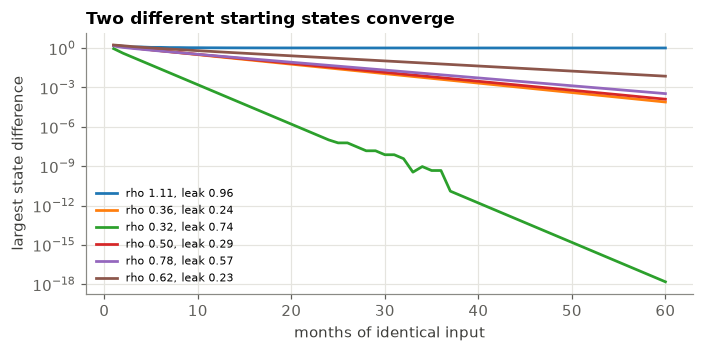

In [5]:
probe = sample_configs(6, SEED)
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for i, cfg in enumerate(probe):
    W = scale_to_rho(lab.A, cfg["rho"], spectral_radius(lab.A))
    rng = np.random.default_rng(1000)
    W_in = rng.uniform(-1, 1, (len(lab.pn), len(FEATURES)))
    gap = echo_state_gap(W, lab.pn, W_in, lab.inp.U, lab.inp.starts, lab.inp.ends, cfg["leak"], cfg["input_scale"])
    ax.semilogy(np.arange(1, len(gap) + 1), gap, label=f"rho {cfg['rho']:.2f}, leak {cfg['leak']:.2f}")
ax.set_xlabel("months of identical input"); ax.set_ylabel("largest state difference"); ax.legend(fontsize=7, frameon=False)
ax.set_title("Two different starting states converge"); plt.tight_layout(); plt.show()

## 4. Pipeline check: the readout reproduces notebook 05's ridge
The fast ridge used here (running Gram matrices, all penalties at once) should match scikit-learn's ridge on the raw features. With the reservoir states removed, the best RMSE should be very close to the ridge row of `results/leaderboard.csv`. If it is not, something is wrong in the readout and no reservoir result can be trusted.

In [6]:
lb = pd.read_csv(RESULTS / "leaderboard.csv")
rows = []
for h in HORIZONS:
    ti, si = lab.loc[h]; Zin = lab.inp.R[ti, si]; trm, vam = lab.masks[h]; y = lab.y[h]
    P = ridge_path(Zin, y, trm, vam)
    r = np.mean([np.sqrt(np.mean((y[va][:, None] - p) ** 2, axis=0)) for va, p in zip(vam, P)], axis=0)
    ref = lb[(lb["horizon"] == h) & (lb["model"] == "ridge")]["rmse"].iloc[0]
    rows.append({"horizon": h, "inputs-only, this readout": r.min(), "ridge in notebook 05": ref, "difference": r.min() - ref})
check = pd.DataFrame(rows).set_index("horizon"); INPUTS_ONLY = check["inputs-only, this readout"].to_dict()
display(check.round(4))
assert (check["difference"].abs() < 0.003).all(), "readout does not reproduce notebook 05's ridge"

,"inputs-only, this readout",ridge in notebook 05,difference
horizon,,,
1,0.5032,0.5033,-0.0001
3,0.5706,0.5707,-0.0001
6,0.6216,0.6216,0.0000
12,0.6887,0.6887,-0.0000


## 5. Random search over the fly reservoir
Each configuration costs one pass of the reservoir over all 178 countries (seconds) plus the readout fits for every horizon, variant and fold. The log is written after every configuration.

In [7]:
CONFIGS = sample_configs(N_ITER, SEED)
print("Search space: rho 0.3-1.4, input_scale 0.02-2 (log), leak 0.1-1.0, state_weight 0.02-1 (log)")
print("First configuration:", {k: round(v, 3) for k, v in CONFIGS[0].items()})
log = tune(lab, "fly", CONFIGS, LOG)
print("Search complete.")

Search space: rho 0.3-1.4, input_scale 0.02-2 (log), leak 0.1-1.0, state_weight 0.02-1 (log)
First configuration: {'input_scale': 0.112, 'leak': 0.956, 'rho': 1.105, 'state_weight': 0.208}
[fly] config 1/40 done  (0.3 min elapsed)
[fly] config 2/40 done  (0.7 min elapsed)
[fly] config 3/40 done  (1.0 min elapsed)
[fly] config 4/40 done  (1.3 min elapsed)
[fly] config 5/40 done  (1.7 min elapsed)
[fly] config 6/40 done  (2.0 min elapsed)
[fly] config 7/40 done  (2.3 min elapsed)
[fly] config 8/40 done  (2.6 min elapsed)
[fly] config 9/40 done  (2.9 min elapsed)
[fly] config 10/40 done  (3.2 min elapsed)
[fly] config 11/40 done  (3.5 min elapsed)
[fly] config 12/40 done  (3.9 min elapsed)
[fly] config 13/40 done  (4.2 min elapsed)
[fly] config 14/40 done  (4.6 min elapsed)
[fly] config 15/40 done  (4.9 min elapsed)
[fly] config 16/40 done  (5.2 min elapsed)
[fly] config 17/40 done  (5.5 min elapsed)
[fly] config 18/40 done  (5.9 min elapsed)
[fly] config 19/40 done  (6.2 min elapsed)
[fl

## 6. Results: the fly reservoir against the baselines

In [8]:
log = pd.read_csv(LOG)
fly = best_configs(log[log["network"] == "fly"])
lb = pd.read_csv(RESULTS / ("leaderboard_quicktest.csv" if QUICK_TEST else "leaderboard.csv"))
tab = lb.pivot(index="horizon", columns="model", values="rmse")
for v, name in [("random", "fly reservoir (1,024 units)"), ("mbon", "fly reservoir (MBONs only)")]:
    tab[name] = fly[fly["variant"] == v].set_index("horizon")["rmse"]
tab["inputs only (same readout)"] = pd.Series(INPUTS_ONLY)
tab = tab.loc[HORIZONS, ["naive (best window)", "ridge", "random forest", "gradient boosting", "inputs only (same readout)",
                         "fly reservoir (1,024 units)", "fly reservoir (MBONs only)"]]
display(tab.round(4))
print("Skill vs the tuned naive baseline (1 - RMSE / RMSE naive):")
display((1 - tab.div(tab["naive (best window)"], axis=0)).drop(columns="naive (best window)").round(3))
print("Fly reservoir (1,024 units) minus ridge (negative = reservoir better):")
display((tab["fly reservoir (1,024 units)"] - tab["ridge"]).round(4).to_frame("RMSE difference"))

model,naive (best window),ridge,random forest,gradient boosting,inputs only (same readout),"fly reservoir (1,024 units)",fly reservoir (MBONs only)
horizon,,,,,,,
1,0.5282,0.5033,0.5048,0.5073,0.5032,0.5026,0.5025
3,0.5892,0.5707,0.5783,0.5824,0.5706,0.5702,0.5698
6,0.6320,0.6216,0.6322,0.6354,0.6216,0.6206,0.6202
12,0.7093,0.6887,0.7012,0.7101,0.6887,0.6877,0.6874


Skill vs the tuned naive baseline (1 - RMSE / RMSE naive):


model,ridge,random forest,gradient boosting,inputs only (same readout),"fly reservoir (1,024 units)",fly reservoir (MBONs only)
horizon,,,,,,
1,0.047,0.044,0.040,0.047,0.048,0.049
3,0.031,0.018,0.012,0.031,0.032,0.033
6,0.016,-0.000,-0.005,0.016,0.018,0.019
12,0.029,0.011,-0.001,0.029,0.030,0.031


Fly reservoir (1,024 units) minus ridge (negative = reservoir better):


,RMSE difference
horizon,
1,-0.0007
3,-0.0005
6,-0.0010
12,-0.0010


In [9]:
best_show = fly[fly["variant"] == "random"].copy()
pp = best_show["params"].apply(json.loads).apply(pd.Series)
best_show = pd.concat([best_show[["horizon", "config_id", "rmse", "rmse_sd"]], pp], axis=1)
best_show["ridge lambda"] = [LAMBDAS[i] for i in fly[fly["variant"] == "random"]["lambda_id"]]
def esp_gap(cfg):
    W = scale_to_rho(lab.A, cfg["rho"], spectral_radius(lab.A))
    W_in = np.random.default_rng(1000).uniform(-1, 1, (len(lab.pn), len(FEATURES)))
    return echo_state_gap(W, lab.pn, W_in, lab.inp.U, lab.inp.starts, lab.inp.ends, cfg["leak"], cfg["input_scale"])[-1]
best_show["state gap after 60 months"] = [esp_gap(json.loads(p)) for p in fly[fly["variant"] == "random"]["params"]]
best_show["forgets start state"] = best_show["state gap after 60 months"] < 1e-3
display(best_show.round(4))
print("A configuration that does not forget its starting state (gap stays near 1) is in the chaotic regime: its states reflect where the run began, not only the input history.")
print("Edge check: a best value at the edge of its range means the range should be widened.")
print("  rho 0.3-1.4 | input_scale 0.02-2 | leak 0.1-1.0 | state_weight 0.02-1 | lambda", f"{LAMBDAS[0]:.0e}-{LAMBDAS[-1]:.0e}")

,horizon,config_id,rmse,rmse_sd,input_scale,leak,rho,state_weight,ridge lambda,state gap after 60 months,forgets start state
4,1,27,0.5026,0.0266,0.0574,0.1693,0.6187,0.0376,0.0100,0.0282,False
5,3,27,0.5702,0.0166,0.0574,0.1693,0.6187,0.0376,0.0100,0.0282,False
6,6,27,0.6206,0.0223,0.0574,0.1693,0.6187,0.0376,0.0100,0.0282,False
7,12,27,0.6877,0.0443,0.0574,0.1693,0.6187,0.0376,0.0316,0.0282,False


A configuration that does not forget its starting state (gap stays near 1) is in the chaotic regime: its states reflect where the run began, not only the input history.
Edge check: a best value at the edge of its range means the range should be widened.
  rho 0.3-1.4 | input_scale 0.02-2 | leak 0.1-1.0 | state_weight 0.02-1 | lambda 1e-04-3e+01


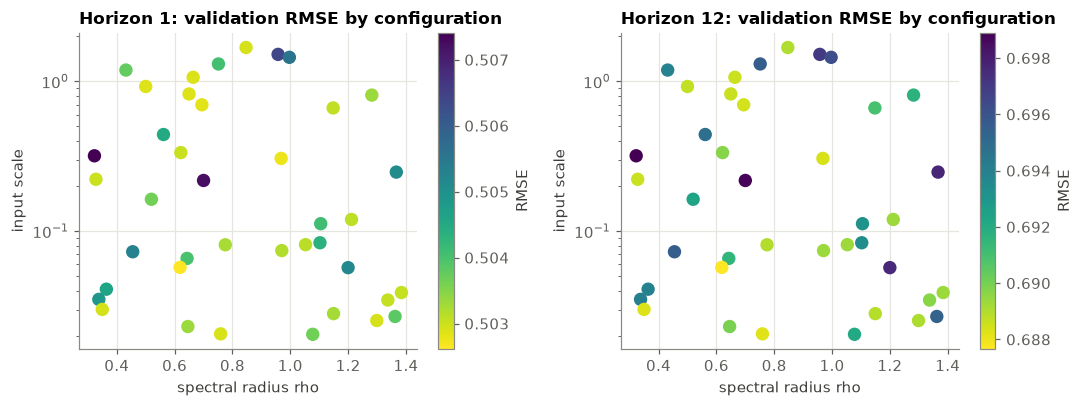

In [10]:
cfg_df = pd.DataFrame(CONFIGS).assign(config_id=lambda d: d.index)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, h in zip(axes, [HORIZONS[0], HORIZONS[-1]]):
    s = (log[(log["network"] == "fly") & (log["variant"] == "random") & (log["horizon"] == h)]
         .groupby(["config_id", "lambda_id", "fold"])["rmse"].mean().groupby(["config_id", "lambda_id"]).mean()
         .groupby("config_id").min().rename("rmse").reset_index().merge(cfg_df, on="config_id"))
    sc = ax.scatter(s["rho"], s["input_scale"], c=s["rmse"], s=60, cmap="viridis_r")
    ax.set_xscale("linear"); ax.set_yscale("log"); ax.set_xlabel("spectral radius rho"); ax.set_ylabel("input scale")
    ax.set_title(f"Horizon {h}: validation RMSE by configuration"); plt.colorbar(sc, ax=ax, label="RMSE")
plt.tight_layout(); plt.show()

In [11]:
fly.round(5).to_csv(RESULTS / ("reservoir_best_fly_quicktest.csv" if QUICK_TEST else "reservoir_best_fly.csv"), index=False)
print("Saved best fly configurations to results/")

Saved best fly configurations to results/


## 7. Reading the results
Fill in after the full run. Check:

- **Does the fly reservoir beat `inputs only (same readout)`?** That row is ridge with no reservoir at all. If the reservoir does not beat it, the states add nothing beyond the raw features.
- **Is any gain larger than the fold spread?** Notebook 08 runs the paired bootstrap, the control networks and multiple random seeds. Do not claim a fly advantage from this table alone: a random reservoir might do the same.
- **MBON-only against 1,024 random units:** if 96 MBONs approach 1,024 units, the fly's own readout neurons carry most of the useful signal.
- **Edge of range:** widen any range where the best value sits at a boundary and resume the search.